# 02 - Tyre wear and fuel burn

Exploring the cleaned laps (`data/laps_clean.parquet`, from `python -m f1lab.clean`) to see how tyre age and fuel load show up in lap times. The aim is to decide how the lap-time model should be built.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

pd.set_option("display.width", 160)
c = pd.read_parquet("../data/laps_clean.parquet")
c["race"] = c["season"].astype(str) + "-" + c["round"].astype(str)
c["tyre_age"] = c["tyre_age"].astype(float)
c["rel"] = c["lap_time_s"] / c.groupby("race")["lap_time_s"].transform("median")
len(c), c["race"].nunique()

(81476, 90)

## The naive view

Median lap time (relative to the race median) by tyre age, per compound. Only ages with at least 50 laps are shown.

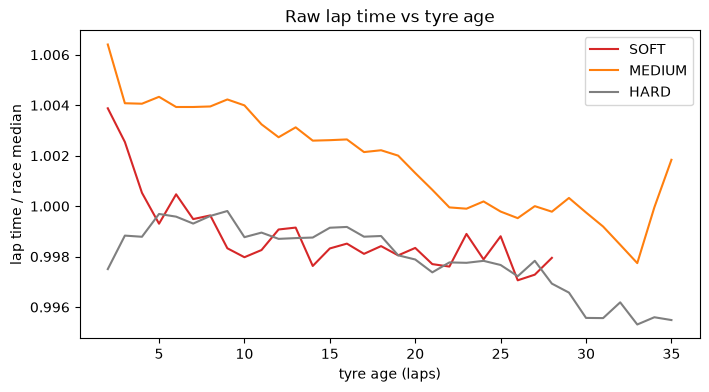

tyre_age,"(0, 5]","(5, 10]","(10, 20]","(20, 35]"
compound,,,,
HARD,0.9989,0.9994,0.9987,0.9969
MEDIUM,1.0047,1.0040,1.0026,0.9998
SOFT,1.0015,0.9992,0.9984,0.9985


In [2]:
fig, ax = plt.subplots(figsize=(8, 4))
for comp, colour in (("SOFT", "tab:red"), ("MEDIUM", "tab:orange"), ("HARD", "tab:gray")):
    g = c[(c["compound"] == comp) & (c["tyre_age"] <= 35)]
    s = g.groupby("tyre_age")["rel"].agg(["median", "size"])
    s = s[s["size"] >= 50]
    ax.plot(s.index, s["median"], label=comp, color=colour)
ax.set_xlabel("tyre age (laps)")
ax.set_ylabel("lap time / race median")
ax.legend()
ax.set_title("Raw lap time vs tyre age")
plt.show()
naive = c[c["tyre_age"] <= 35].groupby(["compound", pd.cut(c["tyre_age"], [0, 5, 10, 20, 35])], observed=True)["rel"].median().unstack().round(4)
naive

Read naively, this says tyres get *faster* as they age: HARD goes from 0.9989 of
race pace in its first five laps to 0.9969 after lap 20, and MEDIUM from 1.0047 to
0.9998. That cannot be right physically. The cars burn fuel and get lighter every
lap, and that gain is larger than the wear, so it hides the degradation. Anything
that ignores fuel will learn the wrong sign.

## Separating tyre wear from fuel burn

Tyre age and lap number rise together, so they are collinear. A regression with race and driver fixed effects (which absorb track, car and driver pace) can include lap number as the fuel-burn proxy and give each compound its own wear slope.

In [3]:
def design(d, with_lap=True):
    X = pd.get_dummies(d[["race", "driver"]], drop_first=True).astype(float)
    if with_lap:
        X["lap_number"] = d["lap_number"]
    for comp in ("SOFT", "MEDIUM", "HARD"):
        X[f"age_{comp}"] = np.where(d["compound"] == comp, d["tyre_age"], 0.0)
        if comp != "HARD":
            X[f"offset_{comp}"] = (d["compound"] == comp).astype(float)
    return X

def fit(d, with_lap):
    X = design(d, with_lap)
    m = LinearRegression().fit(X, d["lap_time_s"])
    return pd.Series(m.coef_, X.columns), m.score(X, d["lap_time_s"])

with_fuel, r2 = fit(c, True)
no_fuel, _ = fit(c, False)
pd.DataFrame(
    {
        "ignoring fuel (s/lap)": no_fuel[["age_SOFT", "age_MEDIUM", "age_HARD"]],
        "with fuel proxy (s/lap)": with_fuel[["age_SOFT", "age_MEDIUM", "age_HARD"]],
    }
).round(4), round(with_fuel["lap_number"], 4), round(r2, 3)

(            ignoring fuel (s/lap)  with fuel proxy (s/lap)
 age_SOFT                  -0.0058                   0.0468
 age_MEDIUM                -0.0279                   0.0228
 age_HARD                  -0.0158                   0.0276,
 np.float64(-0.0512),
 0.982)

Ignoring fuel, every compound shows *negative* wear (-0.006 to -0.028 s/lap). With a
fuel proxy, the fuel term is about -0.051 s per lap and wear becomes positive:
SOFT 0.047, MEDIUM 0.023 and HARD 0.028 s per lap. Magnitudes are plausible.

Two cautions. The R-squared of 0.98 is mostly the race and driver fixed effects
and says little about the wear terms. And HARD wearing *faster* than MEDIUM is the
opposite of expectation. One global slope per compound is too crude: hard tyres run
longer stints, often at different fuel loads and track conditions than mediums. This
is a reason to model tracks separately instead of pooling them.

## Does wear vary by race?

The same regression run separately per race (medium and hard only, which most races have enough of).

In [4]:
rows = []
for race, g in c[c["compound"].isin(["MEDIUM", "HARD"])].groupby("race"):
    if len(g) < 300 or g["tyre_age"].nunique() < 10:
        continue
    X = pd.get_dummies(g[["driver", "compound"]], drop_first=True).astype(float)
    X["lap"], X["age"] = g["lap_number"], g["tyre_age"]
    coef = LinearRegression().fit(X, g["lap_time_s"]).coef_
    cols = list(X.columns)
    rows.append((race, g["track"].iloc[0], g["season"].iloc[0], g["track_temp"].mean(), coef[cols.index("age")], coef[cols.index("lap")]))
per_race = pd.DataFrame(rows, columns=["race", "track", "season", "temp", "wear", "fuel"])
per_race.sort_values("wear").iloc[[0, 1, 2, -3, -2, -1]].round(3)

,race,track,season,temp,wear,fuel
10,2022-20,Mexico City,2022,39.385,-0.069,0.066
64,2025-10,Montreal,2025,49.832,-0.043,-0.022
55,2024-23,Lusail,2024,22.455,-0.031,-0.066
5,2022-14,Spa-Francorchamps,2022,36.330,0.161,-0.078
24,2023-13,Spa-Francorchamps,2023,28.935,0.209,-0.105
66,2025-13,Spa-Francorchamps,2025,24.674,1.252,-1.340


Wear estimated race by race ranges from slightly negative to well above 0.2 s per
lap, with one value above 1.

A wear of over a second per lap is not tyre wear. Looking at 2025 Spa:

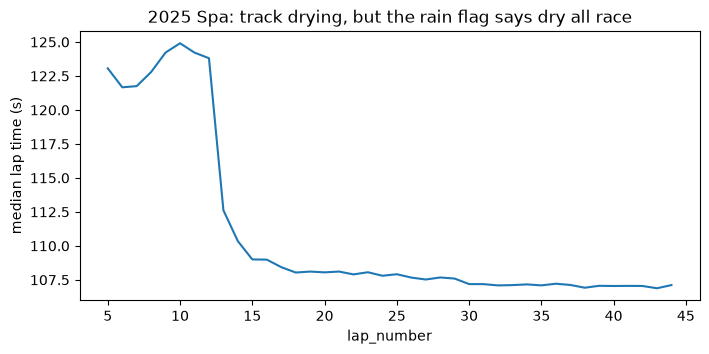

share of laps flagged as rain in the raw data for this race: 0.0


lap_number
(0, 10]     123.0
(10, 20]    108.8
(20, 30]    107.7
(30, 44]    107.1
Name: lap_time_s, dtype: float64

In [5]:
spa = c[c["race"] == "2025-13"]
raw = pd.read_parquet("../data/laps.parquet")
flag = raw[(raw["season"] == 2025) & (raw["round"] == 13)]["rainfall"].mean()
fig, ax = plt.subplots(figsize=(8, 3.5))
spa.groupby("lap_number")["lap_time_s"].median().plot(ax=ax)
ax.set_ylabel("median lap time (s)")
ax.set_title("2025 Spa: track drying, but the rain flag says dry all race")
plt.show()
print("share of laps flagged as rain in the raw data for this race:", flag)
spa.groupby(pd.cut(spa["lap_number"], [0, 10, 20, 30, 44]), observed=True)["lap_time_s"].median().round(1)

2025 Spa is not tyre wear. The first ten laps are about 123 s against about 107 s
later: a wet start on a drying track. Yet the raw rain flag is 0.0 for the whole
race, so the cleaning step could not remove it. **The OpenF1 rain flag is not
reliable**, and a drying track looks like huge negative fuel and huge positive wear.
This race is excluded from the analysis below, and the lap-time model will need a
guard against it (an exclusion list or a feature for drying conditions).

races: 85 | wear median 0.047 s/lap, IQR 0.026 to 0.065
fuel median -0.058 s/lap
corr(track temp, wear): pearson -0.08, spearman -0.04


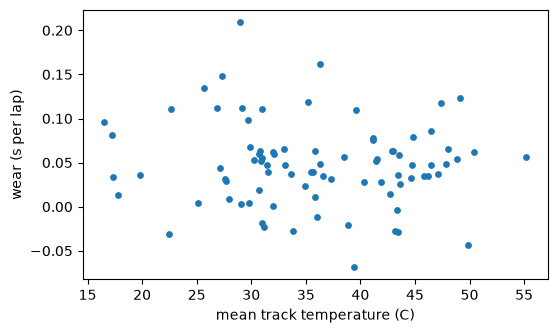

In [6]:
robust = per_race[per_race["race"] != "2025-13"]
print(f"races: {len(robust)} | wear median {robust['wear'].median():.3f} s/lap, "
      f"IQR {robust['wear'].quantile(.25):.3f} to {robust['wear'].quantile(.75):.3f}")
print(f"fuel median {robust['fuel'].median():.3f} s/lap")
print(f"corr(track temp, wear): pearson {robust['temp'].corr(robust['wear']):.2f}, "
      f"spearman {robust['temp'].corr(robust['wear'], method='spearman'):.2f}")
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.scatter(robust["temp"], robust["wear"], s=15)
ax.set_xlabel("mean track temperature (C)")
ax.set_ylabel("wear (s per lap)")
plt.show()

Across 85 races the median wear is 0.047 s per lap (IQR 0.026 to 0.065) and median fuel
effect is -0.058 s per lap. Surprisingly, track temperature shows essentially no
relationship with wear (Pearson -0.08, Spearman -0.04). I would not conclude that
temperature does not matter: this is a crude per-race estimate, noisy, and a
track's mean temperature is tangled up with the track itself. It does mean
temperature is unlikely to be a strong standalone predictor.

## Is wear a property of the track?

If wear were mostly track-specific, the same track should show similar wear in different seasons.

In [7]:
by_track = robust.pivot_table(index="track", columns="season", values="wear")
print("correlation of per-track wear between seasons:")
display(by_track.corr().round(2))
avg = robust.groupby("track")["wear"].mean().sort_values()
avg.round(3).iloc[[0, 1, 2, -3, -2, -1]]

correlation of per-track wear between seasons:


season,2022,2023,2024,2025
season,,,,
2022,1.00,0.70,0.30,0.46
2023,0.70,1.00,0.15,0.62
2024,0.30,0.15,1.00,0.13
2025,0.46,0.62,0.13,1.00


track
Monte Carlo         -0.003
Melbourne            0.007
Lusail               0.012
Suzuka               0.088
Sakhir               0.117
Spa-Francorchamps    0.144
Name: wear, dtype: float64

Wear is partly a property of the track but noisy. Per-track wear correlates 0.70
between 2022 and 2023, 0.62 between 2023 and 2025 and 0.46 between 2022 and 2025,
but only 0.13 to 0.30 with 2024. Monte Carlo (-0.003), Melbourne (0.007) and Lusail
(0.012) show almost no measurable wear; Spa (0.144), Sakhir (0.117) and Suzuka
(0.088) the most. Tracks are not stable enough to trust blindly, so the model should
learn a track effect but shrink it toward the overall average.

## What this means for the lap-time model
1. Include lap number (a fuel proxy) explicitly. Ignoring it flips the sign of wear.
2. Let wear differ by compound and by track, with the track effect shrunk toward the
   global average because it is noisy across seasons.
3. Do not rely on track temperature as a main driver.
4. Guard against drying-track races. The rain flag cannot be trusted, so an
   exclusion list or a pace-based detector is needed.
5. Evaluate on held-out seasons, since the per-track picture shifts year to year.